# Factory-to-Customer Shipping Route Efficiency Analysis

## Nassau Candy Distributor

### Unified Mentor - Machine Learning Internship Project

---

## 1. Project Overview

Nassau Candy Distributor operates a network of factories that supply
products to customers across different geographic regions.

This project analyzes the company's shipment data to evaluate
factory-to-customer shipping route efficiency, identify geographic
bottlenecks, compare shipping modes, and generate actionable business
insights.

The analysis includes data cleaning, validation, feature engineering,
exploratory data analysis, route-level performance analysis, geographic
analysis, and interactive visualization.

The final outcome will be an interactive Streamlit dashboard that allows
users to explore shipping performance using different filters and
performance indicators.

## Project Objectives

- Clean and validate the shipment dataset.
- Analyze order and shipment dates.
- Calculate shipping lead time.
- Map products to their respective factories.
- Analyze factory-to-customer shipping routes.
- Identify efficient and inefficient routes.
- Identify geographic shipping bottlenecks.
- Compare different shipping modes.
- Develop route-level performance KPIs.
- Build an interactive Streamlit dashboard.
- Provide actionable recommendations for improving shipping efficiency.

In [2]:
# Import required libraries

import pandas as pd
import numpy as np

import matplotlib.pyplot as plt
import seaborn as sns

import plotly.express as px
import plotly.graph_objects as go

from pathlib import Path

import warnings
warnings.filterwarnings("ignore")

print("All libraries imported successfully!")

All libraries imported successfully!


## 2. Load Dataset

In [8]:
# Define the path to the dataset

DATA_PATH = Path("../data/Nassau Candy Distributor.csv")

# Load the dataset
df = pd.read_csv(DATA_PATH)

print("Dataset loaded successfully!")

Dataset loaded successfully!


In [7]:
from pathlib import Path

print("Current working directory:")
print(Path.cwd())

Current working directory:
f:\Nassau_Candy_Shipping_Analysis\notebook


In [9]:
print("Number of rows:", df.shape[0])
print("Number of columns:", df.shape[1])

Number of rows: 10194
Number of columns: 18


In [10]:
from pathlib import Path

print("Current working directory:")
print(Path.cwd())

Current working directory:
f:\Nassau_Candy_Shipping_Analysis\notebook


## 3. Initial Dataset Inspection

Before cleaning the dataset, we inspect its structure, columns, data types,
statistical characteristics, missing values, and duplicate records.

In [11]:
# Display the first five records

df.head()

,Row ID,Order ID,Order Date,Ship Date,Ship Mode,Customer ID,Country/Region,City,State/Province,Postal Code,Division,Region,Product ID,Product Name,Sales,Units,Gross Profit,Cost
0,1,US-2021-103800-CHO-MIL-31000,03-01-2024,30-06-2026,Standard Class,103800,United States,Houston,Texas,77095,Chocolate,Interior,CHO-MIL-31000,Wonka Bar - Milk Chocolate,6.50,2,4.22,2.28
1,2,US-2021-112326-CHO-TRI-54000,04-01-2024,01-07-2026,Standard Class,112326,United States,Naperville,Illinois,60540,Chocolate,Interior,CHO-TRI-54000,Wonka Bar - Triple Dazzle Caramel,7.50,2,4.90,2.60
2,3,US-2021-112326-CHO-NUT-13000,04-01-2024,01-07-2026,Standard Class,112326,United States,Naperville,Illinois,60540,Chocolate,Interior,CHO-NUT-13000,Wonka Bar - Nutty Crunch Surprise,10.47,3,7.47,3.00
3,4,US-2021-112326-CHO-SCR-58000,04-01-2024,01-07-2026,Standard Class,112326,United States,Naperville,Illinois,60540,Chocolate,Interior,CHO-SCR-58000,Wonka Bar -Scrumdiddlyumptious,10.80,3,7.50,3.30
4,5,US-2021-141817-CHO-TRI-54000,05-01-2024,05-07-2026,Standard Class,141817,United States,Philadelphia,Pennsylvania,19143,Chocolate,Atlantic,CHO-TRI-54000,Wonka Bar - Triple Dazzle Caramel,11.25,3,7.35,3.90


In [12]:
# Display the last five records

df.tail()

,Row ID,Order ID,Order Date,Ship Date,Ship Mode,Customer ID,Country/Region,City,State/Province,Postal Code,Division,Region,Product ID,Product Name,Sales,Units,Gross Profit,Cost
10189,10190,US-2024-143259-CHO-MIL-31000,30-12-2025,26-06-2030,Standard Class,143259,United States,New York City,New York,10009,Chocolate,Atlantic,CHO-MIL-31000,Wonka Bar - Milk Chocolate,9.75,3,6.33,3.42
10190,10191,US-2024-115427-CHO-NUT-13000,30-12-2025,26-06-2030,Standard Class,115427,United States,Fairfield,California,94533,Chocolate,Pacific,CHO-NUT-13000,Wonka Bar - Nutty Crunch Surprise,6.98,2,4.98,2.00
10191,10192,US-2024-156720-CHO-SCR-58000,30-12-2025,26-06-2030,Standard Class,156720,United States,Loveland,Colorado,80538,Chocolate,Pacific,CHO-SCR-58000,Wonka Bar -Scrumdiddlyumptious,10.80,3,7.50,3.30
10192,10193,US-2024-143259-CHO-TRI-54000,30-12-2025,26-06-2030,Standard Class,143259,United States,New York City,New York,10009,Chocolate,Atlantic,CHO-TRI-54000,Wonka Bar - Triple Dazzle Caramel,26.25,7,17.15,9.10
10193,10194,CA-2024-143500-CHO-SCR-58000,30-12-2025,26-06-2030,Standard Class,143500,Canada,Charlottetown,Prince Edward Island,C0A,Chocolate,Atlantic,CHO-SCR-58000,Wonka Bar -Scrumdiddlyumptious,10.80,3,7.50,3.30


In [13]:
# Display all column names

print("Dataset Columns:\n")

for i, column in enumerate(df.columns, start=1):
    print(f"{i}. {column}")

Dataset Columns:

1. Row ID
2. Order ID
3. Order Date
4. Ship Date
5. Ship Mode
6. Customer ID
7. Country/Region
8. City
9. State/Province
10. Postal Code
11. Division
12. Region
13. Product ID
14. Product Name
15. Sales
16. Units
17. Gross Profit
18. Cost


In [14]:
# Display dataset information and data types

df.info()

<class 'pandas.DataFrame'>
RangeIndex: 10194 entries, 0 to 10193
Data columns (total 18 columns):
 #   Column          Non-Null Count  Dtype  
---  ------          --------------  -----  
 0   Row ID          10194 non-null  int64  
 1   Order ID        10194 non-null  str    
 2   Order Date      10194 non-null  str    
 3   Ship Date       10194 non-null  str    
 4   Ship Mode       10194 non-null  str    
 5   Customer ID     10194 non-null  int64  
 6   Country/Region  10194 non-null  str    
 7   City            10194 non-null  str    
 8   State/Province  10194 non-null  str    
 9   Postal Code     10194 non-null  str    
 10  Division        10194 non-null  str    
 11  Region          10194 non-null  str    
 12  Product ID      10194 non-null  str    
 13  Product Name    10194 non-null  str    
 14  Sales           10194 non-null  float64
 15  Units           10194 non-null  int64  
 16  Gross Profit    10194 non-null  float64
 17  Cost            10194 non-null  float64
dt

In [15]:
# Statistical summary of numerical columns

df.describe()

,Row ID,Customer ID,Sales,Units,Gross Profit,Cost
count,10194.000000,10194.000000,10194.000000,10194.000000,10194.000000,10194.000000
mean,5097.500000,134468.961154,13.908537,3.791838,9.166451,4.742087
std,2942.898656,20231.483007,11.341020,2.228317,6.643740,5.061647
min,1.000000,100006.000000,1.250000,1.000000,0.250000,0.600000
25%,2549.250000,117212.000000,7.200000,2.000000,4.900000,2.400000
50%,5097.500000,133550.000000,10.800000,3.000000,7.470000,3.600000
75%,7645.750000,152051.000000,18.000000,5.000000,12.250000,5.700000
max,10194.000000,192314.000000,260.000000,14.000000,130.000000,130.000000


## 4. Data Quality Analysis

This section checks the dataset for missing values and duplicate records
before any cleaning operations are performed.

In [16]:
# Calculate missing values and their percentage

missing_data = pd.DataFrame({
    "Missing Values": df.isnull().sum(),
    "Missing Percentage": (
        df.isnull().sum() / len(df) * 100
    ).round(2)
})

missing_data

,Missing Values,Missing Percentage
Row ID,0,0.0
Order ID,0,0.0
Order Date,0,0.0
Ship Date,0,0.0
Ship Mode,0,0.0
Customer ID,0,0.0
Country/Region,0,0.0
City,0,0.0
State/Province,0,0.0
Postal Code,0,0.0


In [17]:
# Check for duplicate rows

duplicate_count = df.duplicated().sum()

print("Number of duplicate rows:", duplicate_count)

Number of duplicate rows: 0


## 5. Categorical Data Analysis

In [18]:
# Distribution of shipping modes

df["Ship Mode"].value_counts()

Ship Mode
Standard Class    6120
Second Class      1979
First Class       1548
Same Day           547
Name: count, dtype: int64

In [19]:
# Distribution of regions

df["Region"].value_counts()

Region
Pacific     3253
Atlantic    2986
Interior    2335
Gulf        1620
Name: count, dtype: int64

In [20]:
# Distribution of product divisions

df["Division"].value_counts()

Division
Chocolate    9844
Other         310
Sugar          40
Name: count, dtype: int64

In [21]:
# Distribution of countries/regions

df["Country/Region"].value_counts()

Country/Region
United States    9994
Canada            200
Name: count, dtype: int64

In [22]:
# Number of unique products

print("Unique Products:", df["Product ID"].nunique())

Unique Products: 15


In [23]:
# Number of unique states/provinces

print("Unique States/Provinces:", df["State/Province"].nunique())

Unique States/Provinces: 59


## 6. Exploratory Data Analysis

### Shipment Distribution by Shipping Mode

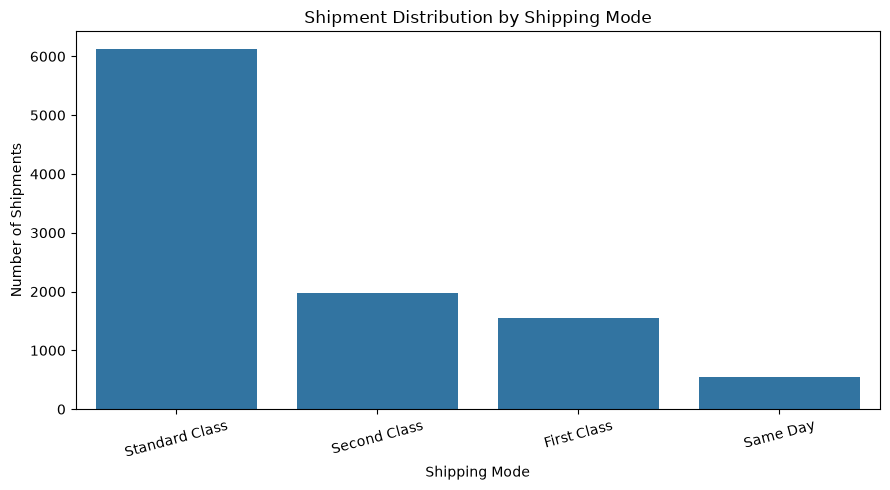

In [24]:
# Shipment distribution by shipping mode

plt.figure(figsize=(9, 5))

sns.countplot(
    data=df,
    x="Ship Mode",
    order=df["Ship Mode"].value_counts().index
)

plt.title("Shipment Distribution by Shipping Mode")
plt.xlabel("Shipping Mode")
plt.ylabel("Number of Shipments")
plt.xticks(rotation=15)
plt.tight_layout()
plt.show()

### Shipment Distribution by Region

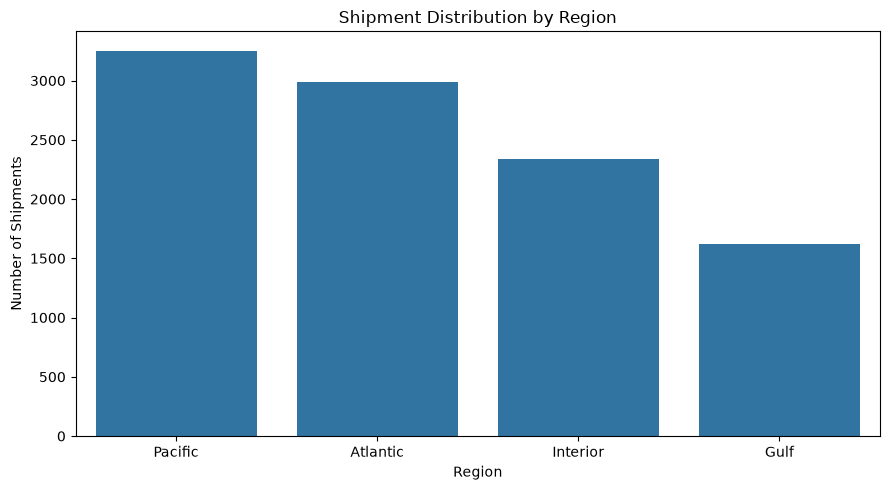

In [25]:
# Shipment distribution by region

plt.figure(figsize=(9, 5))

sns.countplot(
    data=df,
    x="Region",
    order=df["Region"].value_counts().index
)

plt.title("Shipment Distribution by Region")
plt.xlabel("Region")
plt.ylabel("Number of Shipments")
plt.tight_layout()
plt.show()

## 7. Date Validation

The order and shipment dates are converted to datetime format so that
shipping lead time can be calculated accurately.

Date consistency is also checked to identify invalid or unusual shipment
records.

In [26]:
# Convert date columns to datetime

df["Order Date"] = pd.to_datetime(
    df["Order Date"],
    dayfirst=True,
    errors="coerce"
)

df["Ship Date"] = pd.to_datetime(
    df["Ship Date"],
    dayfirst=True,
    errors="coerce"
)

print("Order Date type:", df["Order Date"].dtype)
print("Ship Date type:", df["Ship Date"].dtype)

Order Date type: datetime64[us]
Ship Date type: datetime64[us]


In [27]:
# Check date ranges

print("Order Date range:")
print(df["Order Date"].min(), "to", df["Order Date"].max())

print("\nShip Date range:")
print(df["Ship Date"].min(), "to", df["Ship Date"].max())

Order Date range:
2024-01-02 00:00:00 to 2025-12-31 00:00:00

Ship Date range:
2026-06-30 00:00:00 to 2030-06-28 00:00:00


In [28]:
# Calculate shipping lead time in days

df["Shipping Lead Time"] = (
    df["Ship Date"] - df["Order Date"]
).dt.days

print(df["Shipping Lead Time"].describe())

count    10194.000000
mean      1320.841868
std        262.444892
min        904.000000
25%       1271.000000
50%       1274.000000
75%       1638.000000
max       1642.000000
Name: Shipping Lead Time, dtype: float64


In [29]:
# Check unusual lead times

print("Negative lead times:",
      (df["Shipping Lead Time"] < 0).sum())

print("Zero-day shipments:",
      (df["Shipping Lead Time"] == 0).sum())

print("Shipments over 30 days:",
      (df["Shipping Lead Time"] > 30).sum())

Negative lead times: 0
Zero-day shipments: 0
Shipments over 30 days: 10194


## 8. Investigation of Shipping Lead Time Anomaly

The initial validation shows that all shipment records have a shipping
lead time greater than 30 days. The calculated lead time ranges from
904 to 1,642 days, which is unusually high for normal shipment
processing.

Therefore, the records are not removed at this stage. Instead, the
date relationship is investigated and a data-quality flag is created
so that the original data remains preserved.

In [37]:
# Display sample records with their calculated lead time

df[
    [
        "Order ID",
        "Order Date",
        "Ship Date",
        "Ship Mode",
        "Product Name",
        "Shipping Lead Time"
    ]
].head(10)

,Order ID,Order Date,Ship Date,Ship Mode,Product Name,Shipping Lead Time
0,US-2021-103800-CHO-MIL-31000,2024-01-03,2026-06-30,Standard Class,Wonka Bar - Milk Chocolate,909
1,US-2021-112326-CHO-TRI-54000,2024-01-04,2026-07-01,Standard Class,Wonka Bar - Triple Dazzle Caramel,909
2,US-2021-112326-CHO-NUT-13000,2024-01-04,2026-07-01,Standard Class,Wonka Bar - Nutty Crunch Surprise,909
3,US-2021-112326-CHO-SCR-58000,2024-01-04,2026-07-01,Standard Class,Wonka Bar -Scrumdiddlyumptious,909
4,US-2021-141817-CHO-TRI-54000,2024-01-05,2026-07-05,Standard Class,Wonka Bar - Triple Dazzle Caramel,912
5,US-2021-167199-CHO-SCR-58000,2024-01-06,2026-07-03,Standard Class,Wonka Bar -Scrumdiddlyumptious,909
6,US-2021-167199-CHO-TRI-54000,2024-01-06,2026-07-03,Standard Class,Wonka Bar - Triple Dazzle Caramel,909
7,US-2021-106054-CHO-MIL-31000,2024-01-06,2026-06-30,First Class,Wonka Bar - Milk Chocolate,906
8,US-2021-167199-CHO-NUT-13000,2024-01-06,2026-07-03,Standard Class,Wonka Bar - Nutty Crunch Surprise,909
9,US-2021-167199-CHO-MIL-31000,2024-01-06,2026-07-03,Standard Class,Wonka Bar - Milk Chocolate,909


In [31]:
# Examine the distribution of shipping lead time

df["Shipping Lead Time"].value_counts().sort_index().head(20)

Shipping Lead Time
904       89
905       40
906      289
907      176
908      591
909      519
910      207
911      134
912        4
915        2
1269     258
1270     156
1271     610
1272     456
1273    1326
1274    1035
1275     612
1276     293
1277      18
1634       3
Name: count, dtype: int64

In [32]:
# Examine the largest lead times

df["Shipping Lead Time"].value_counts().sort_index(ascending=False).head(20)

Shipping Lead Time
1642     197
1641     397
1640     657
1639     896
1638     411
1637     449
1636     190
1635     179
1634       3
1277      18
1276     293
1275     612
1274    1035
1273    1326
1272     456
1271     610
1270     156
1269     258
915        2
912        4
Name: count, dtype: int64

In [33]:
# Create a data-quality flag for unusually long lead times

df["Date Quality Flag"] = np.where(
    df["Shipping Lead Time"] > 30,
    "Potential Date Anomaly",
    "Valid"
)

df["Date Quality Flag"].value_counts()

Date Quality Flag
Potential Date Anomaly    10194
Name: count, dtype: int64

In [34]:
# Check for missing or invalid dates after conversion

print("Missing Order Dates:", df["Order Date"].isna().sum())
print("Missing Ship Dates:", df["Ship Date"].isna().sum())

Missing Order Dates: 0
Missing Ship Dates: 0


In [35]:
# Check whether any shipment date occurs before the order date

invalid_date_order = (
    df["Ship Date"] < df["Order Date"]
).sum()

print("Ship dates before order dates:", invalid_date_order)

Ship dates before order dates: 0


In [36]:
# Create a date validation summary

date_validation = pd.DataFrame({
    "Validation Check": [
        "Missing Order Dates",
        "Missing Ship Dates",
        "Negative Lead Times",
        "Zero-Day Shipments",
        "Lead Time > 30 Days",
        "Minimum Lead Time",
        "Median Lead Time",
        "Maximum Lead Time"
    ],
    "Result": [
        df["Order Date"].isna().sum(),
        df["Ship Date"].isna().sum(),
        (df["Shipping Lead Time"] < 0).sum(),
        (df["Shipping Lead Time"] == 0).sum(),
        (df["Shipping Lead Time"] > 30).sum(),
        df["Shipping Lead Time"].min(),
        df["Shipping Lead Time"].median(),
        df["Shipping Lead Time"].max()
    ]
})

date_validation

,Validation Check,Result
0,Missing Order Dates,0.0
1,Missing Ship Dates,0.0
2,Negative Lead Times,0.0
3,Zero-Day Shipments,0.0
4,Lead Time > 30 Days,10194.0
5,Minimum Lead Time,904.0
6,Median Lead Time,1274.0
7,Maximum Lead Time,1642.0


In [38]:
df["Shipping Lead Time"].value_counts().sort_index().head(20)

Shipping Lead Time
904       89
905       40
906      289
907      176
908      591
909      519
910      207
911      134
912        4
915        2
1269     258
1270     156
1271     610
1272     456
1273    1326
1274    1035
1275     612
1276     293
1277      18
1634       3
Name: count, dtype: int64

In [39]:
df["Shipping Lead Time"].value_counts().sort_index(ascending=False).head(20)

Shipping Lead Time
1642     197
1641     397
1640     657
1639     896
1638     411
1637     449
1636     190
1635     179
1634       3
1277      18
1276     293
1275     612
1274    1035
1273    1326
1272     456
1271     610
1270     156
1269     258
915        2
912        4
Name: count, dtype: int64

## 9. Date Quality Flag

Since all records have a calculated lead time greater than 30 days, the
records are flagged for potential date anomalies rather than being
deleted.

The original order and shipment dates are preserved.

In [40]:
# Create a data-quality flag for unusually long lead times

df["Date Quality Flag"] = np.where(
    df["Shipping Lead Time"] > 30,
    "Potential Date Anomaly",
    "Valid"
)

# Display the distribution
df["Date Quality Flag"].value_counts()

Date Quality Flag
Potential Date Anomaly    10194
Name: count, dtype: int64

In [41]:
# Check for missing dates

print("Missing Order Dates:",
      df["Order Date"].isna().sum())

print("Missing Ship Dates:",
      df["Ship Date"].isna().sum())

# Check for chronological inconsistencies

print("Ship Date before Order Date:",
      (df["Ship Date"] < df["Order Date"]).sum())

Missing Order Dates: 0
Missing Ship Dates: 0
Ship Date before Order Date: 0


## 10. Product-to-Factory Mapping

The dataset contains product information but does not directly provide a
factory field. Therefore, products are mapped to their corresponding
manufacturing factories using the project-provided factory mapping.

This mapping will be used to construct factory-to-customer shipping routes.

In [42]:
# Inspect unique product names

products = sorted(df["Product Name"].dropna().unique())

print("Number of unique products:", len(products))
print("\nProduct Names:\n")

for i, product in enumerate(products, start=1):
    print(f"{i}. {product}")

Number of unique products: 15

Product Names:

1. Everlasting Gobstopper
2. Fizzy Lifting Drinks
3. Fun Dip
4. Hair Toffee
5. Kazookles
6. Laffy Taffy
7. Lickable Wallpaper
8. Nerds
9. SweeTARTS
10. Wonka Bar - Fudge Mallows
11. Wonka Bar - Milk Chocolate
12. Wonka Bar - Nutty Crunch Surprise
13. Wonka Bar - Triple Dazzle Caramel
14. Wonka Bar -Scrumdiddlyumptious
15. Wonka Gum


In [43]:
# Check the relationship between Product ID and Product Name

product_mapping_check = (
    df[["Product ID", "Product Name"]]
    .drop_duplicates()
    .sort_values("Product ID")
)

print("Unique Product ID / Product Name combinations:",
      len(product_mapping_check))

product_mapping_check.head(20)

Unique Product ID / Product Name combinations: 15


,Product ID,Product Name
13,CHO-FUD-51000,Wonka Bar - Fudge Mallows
0,CHO-MIL-31000,Wonka Bar - Milk Chocolate
2,CHO-NUT-13000,Wonka Bar - Nutty Crunch Surprise
3,CHO-SCR-58000,Wonka Bar -Scrumdiddlyumptious
1,CHO-TRI-54000,Wonka Bar - Triple Dazzle Caramel
191,OTH-FIZ-56000,Fizzy Lifting Drinks
19,OTH-GUM-21000,Wonka Gum
26,OTH-KAZ-38000,Kazookles
136,OTH-LIC-15000,Lickable Wallpaper
4729,SUG-EVE-47000,Everlasting Gobstopper


## 11. Product-to-Factory Mapping

Each product is associated with its manufacturing factory. This mapping
allows the shipment data to be transformed into factory-to-customer
routes for route efficiency analysis.

In [45]:
factory_mapping = {
    "Wonka Bar - Nutty Crunch Surprise": "Lot's O' Nuts",
    "Wonka Bar - Fudge Mallows": "Lot's O' Nuts",
    "Wonka Bar -Scrumdiddlyumptious": "Lot's O' Nuts",

    "Wonka Bar - Milk Chocolate": "Wicked Choccy's",
    "Wonka Bar - Triple Dazzle Caramel": "Wicked Choccy's",

    "Laffy Taffy": "Sugar Shack",
    "SweeTARTS": "Sugar Shack",
    "Nerds": "Sugar Shack",
    "Fun Dip": "Sugar Shack",
    "Fizzy Lifting Drinks": "Sugar Shack",

    "Everlasting Gobstopper": "Secret Factory",
    "Lickable Wallpaper": "Secret Factory",
    "Wonka Gum": "Secret Factory",

    "Hair Toffee": "The Other Factory",
    "Kazookles": "The Other Factory"
}

df["Factory"] = df["Product Name"].map(factory_mapping)

print("Missing factory mappings:", df["Factory"].isna().sum())

print("\nFactory distribution:")
print(df["Factory"].value_counts())

Missing factory mappings: 0

Factory distribution:
Factory
Lot's O' Nuts        5692
Wicked Choccy's      4152
Secret Factory        217
The Other Factory     100
Sugar Shack            33
Name: count, dtype: int64


In [46]:
product_factory_check = (
    df[["Product ID", "Product Name", "Factory"]]
    .drop_duplicates()
    .sort_values(["Factory", "Product Name"])
)

product_factory_check

,Product ID,Product Name,Factory
13,CHO-FUD-51000,Wonka Bar - Fudge Mallows,Lot's O' Nuts
2,CHO-NUT-13000,Wonka Bar - Nutty Crunch Surprise,Lot's O' Nuts
3,CHO-SCR-58000,Wonka Bar -Scrumdiddlyumptious,Lot's O' Nuts
4729,SUG-EVE-47000,Everlasting Gobstopper,Secret Factory
136,OTH-LIC-15000,Lickable Wallpaper,Secret Factory
19,OTH-GUM-21000,Wonka Gum,Secret Factory
191,OTH-FIZ-56000,Fizzy Lifting Drinks,Sugar Shack
5007,SUG-FUN-75000,Fun Dip,Sugar Shack
226,SUG-LAF-25000,Laffy Taffy,Sugar Shack
1490,SUG-NER-92000,Nerds,Sugar Shack


In [47]:
factory_summary = (
    df.groupby("Factory")
      .agg(
          Shipments=("Order ID", "count"),
          Units=("Units", "sum"),
          Sales=("Sales", "sum"),
          Gross_Profit=("Gross Profit", "sum"),
          Cost=("Cost", "sum")
      )
      .sort_values("Sales", ascending=False)
)

factory_summary

,Shipments,Units,Sales,Gross_Profit,Cost
Factory,,,,,
Lot's O' Nuts,5692,21412,76340.15,52771.05,23569.10
Wicked Choccy's,4152,15863,55352.75,36053.57,19299.18
Secret Factory,217,884,8587.50,4344.70,4242.80
The Other Factory,100,388,1282.25,152.25,1130.00
Sugar Shack,33,107,220.98,121.23,99.75


In [48]:
factory_summary["Gross_Margin_%"] = (
    factory_summary["Gross_Profit"] / factory_summary["Sales"] * 100
).round(2)

factory_summary

,Shipments,Units,Sales,Gross_Profit,Cost,Gross_Margin_%
Factory,,,,,,
Lot's O' Nuts,5692,21412,76340.15,52771.05,23569.10,69.13
Wicked Choccy's,4152,15863,55352.75,36053.57,19299.18,65.13
Secret Factory,217,884,8587.50,4344.70,4242.80,50.59
The Other Factory,100,388,1282.25,152.25,1130.00,11.87
Sugar Shack,33,107,220.98,121.23,99.75,54.86


In [49]:
df["Lead Time (Days)"] = (
    df["Ship Date"] - df["Order Date"]
).dt.days

df["Lead Time (Days)"].describe()

count    10194.000000
mean      1320.841868
std        262.444892
min        904.000000
25%       1271.000000
50%       1274.000000
75%       1638.000000
max       1642.000000
Name: Lead Time (Days), dtype: float64

In [50]:
print("Negative lead times:", (df["Lead Time (Days)"] < 0).sum())
print("Zero-day shipments:", (df["Lead Time (Days)"] == 0).sum())
print("Shipments over 30 days:", (df["Lead Time (Days)"] > 30).sum())

Negative lead times: 0
Zero-day shipments: 0
Shipments over 30 days: 10194


In [51]:
# Create shipping route
df["Route"] = (
    df["Factory"] + " → " + df["State/Province"].astype(str)
)

# Check the number of unique routes
print("Number of unique routes:", df["Route"].nunique())

# Show a few routes
df["Route"].drop_duplicates().head(20)

Number of unique routes: 196


0            Wicked Choccy's → Texas
1         Wicked Choccy's → Illinois
2           Lot's O' Nuts → Illinois
4     Wicked Choccy's → Pennsylvania
5           Lot's O' Nuts → Kentucky
6         Wicked Choccy's → Kentucky
7          Wicked Choccy's → Georgia
11      Wicked Choccy's → California
18        Wicked Choccy's → Virginia
19         Secret Factory → Virginia
20        Wicked Choccy's → Delaware
22    Lot's O' Nuts → South Carolina
24              Lot's O' Nuts → Ohio
25       Wicked Choccy's → Louisiana
26     The Other Factory → Louisiana
30        Lot's O' Nuts → California
31         Lot's O' Nuts → Louisiana
32     Secret Factory → Pennsylvania
33           Lot's O' Nuts → Georgia
35      Lot's O' Nuts → Pennsylvania
Name: Route, dtype: str

In [52]:
route_summary = (
    df.groupby("Route")
      .agg(
          Route_Volume=("Order ID", "count"),
          Average_Lead_Time=("Lead Time (Days)", "mean"),
          Delayed_Shipments=("Lead Time (Days)", lambda x: (x > 30).sum())
      )
)

route_summary["Delay_Frequency_%"] = (
    route_summary["Delayed_Shipments"] /
    route_summary["Route_Volume"] * 100
).round(2)

route_summary["Average_Lead_Time"] = (
    route_summary["Average_Lead_Time"].round(2)
)

route_summary = route_summary.sort_values(
    "Route_Volume",
    ascending=False
)

route_summary.head(20)

,Route_Volume,Average_Lead_Time,Delayed_Shipments,Delay_Frequency_%
Route,,,,
Lot's O' Nuts → California,1125,1316.91,1125,100.0
Wicked Choccy's → California,823,1320.33,823,100.0
Lot's O' Nuts → New York,645,1330.52,645,100.0
Lot's O' Nuts → Texas,569,1310.46,569,100.0
Wicked Choccy's → New York,436,1311.88,436,100.0
Wicked Choccy's → Texas,388,1315.61,388,100.0
Lot's O' Nuts → Pennsylvania,331,1315.06,331,100.0
Lot's O' Nuts → Washington,269,1343.96,269,100.0
Lot's O' Nuts → Illinois,267,1319.93,267,100.0


In [53]:
# Route Efficiency Score
# Lower average lead time = higher efficiency

min_lead = route_summary["Average_Lead_Time"].min()
max_lead = route_summary["Average_Lead_Time"].max()

route_summary["Route_Efficiency_Score"] = (
    100 * (max_lead - route_summary["Average_Lead_Time"]) /
    (max_lead - min_lead)
).round(2)

route_summary.head(20)

,Route_Volume,Average_Lead_Time,Delayed_Shipments,Delay_Frequency_%,Route_Efficiency_Score
Route,,,,,
Lot's O' Nuts → California,1125,1316.91,1125,100.0,44.17
Wicked Choccy's → California,823,1320.33,823,100.0,43.71
Lot's O' Nuts → New York,645,1330.52,645,100.0,42.32
Lot's O' Nuts → Texas,569,1310.46,569,100.0,45.05
Wicked Choccy's → New York,436,1311.88,436,100.0,44.85
Wicked Choccy's → Texas,388,1315.61,388,100.0,44.35
Lot's O' Nuts → Pennsylvania,331,1315.06,331,100.0,44.42
Lot's O' Nuts → Washington,269,1343.96,269,100.0,40.49
Lot's O' Nuts → Illinois,267,1319.93,267,100.0,43.76


In [54]:
# Show the best-performing routes
best_routes = route_summary.sort_values(
    "Route_Efficiency_Score",
    ascending=False
)

best_routes.head(10)

,Route_Volume,Average_Lead_Time,Delayed_Shipments,Delay_Frequency_%,Route_Efficiency_Score
Route,,,,,
Secret Factory → New Mexico,2,906.0,2,100.0,100.00
Secret Factory → Nebraska,1,906.0,1,100.0,100.00
The Other Factory → Louisiana,1,907.0,1,100.0,99.86
The Other Factory → Connecticut,2,907.5,2,100.0,99.80
Secret Factory → Mississippi,1,908.0,1,100.0,99.73
Wicked Choccy's → Maine,2,908.0,2,100.0,99.73
Secret Factory → Louisiana,2,908.5,2,100.0,99.66
Secret Factory → Minnesota,1,909.0,1,100.0,99.59
Secret Factory → South Carolina,1,909.0,1,100.0,99.59


In [55]:
# Show the least-efficient routes
worst_routes = route_summary.sort_values(
    "Route_Efficiency_Score",
    ascending=True
)

worst_routes.head(10)

,Route_Volume,Average_Lead_Time,Delayed_Shipments,Delay_Frequency_%,Route_Efficiency_Score
Route,,,,,
Sugar Shack → New Jersey,1,1642.0,1,100.0,0.00
Sugar Shack → Connecticut,1,1641.0,1,100.0,0.14
Secret Factory → New Hampshire,1,1641.0,1,100.0,0.14
Wicked Choccy's → West Virginia,2,1639.0,2,100.0,0.41
Lot's O' Nuts → North Dakota,5,1638.2,5,100.0,0.52
Sugar Shack → Washington,1,1638.0,1,100.0,0.54
The Other Factory → Nevada,1,1638.0,1,100.0,0.54
Secret Factory → Connecticut,1,1638.0,1,100.0,0.54
Sugar Shack → California,1,1638.0,1,100.0,0.54


In [56]:
ship_mode_summary = (
    df.groupby("Ship Mode")
      .agg(
          Shipments=("Order ID", "count"),
          Unique_Orders=("Order ID", "nunique"),
          Units=("Units", "sum"),
          Sales=("Sales", "sum"),
          Gross_Profit=("Gross Profit", "sum"),
          Average_Lead_Time=("Lead Time (Days)", "mean")
      )
)

ship_mode_summary["Gross_Margin_%"] = (
    ship_mode_summary["Gross_Profit"] /
    ship_mode_summary["Sales"] * 100
).round(2)

ship_mode_summary["Average_Lead_Time"] = (
    ship_mode_summary["Average_Lead_Time"].round(2)
)

ship_mode_summary = ship_mode_summary.sort_values(
    "Shipments",
    ascending=False
)

ship_mode_summary

,Shipments,Unique_Orders,Units,Sales,Gross_Profit,Average_Lead_Time,Gross_Margin_%
Ship Mode,,,,,,,
Standard Class,6120,5142,23409,85490.35,56424.46,1314.33,66.00
Second Class,1979,1653,7546,27860.22,18306.52,1323.85,65.71
First Class,1548,1312,5724,21319.39,14011.09,1338.28,65.72
Same Day,547,442,1975,7113.67,4700.73,1333.44,66.08


In [57]:
state_summary = (
    df.groupby("State/Province")
      .agg(
          Shipments=("Order ID", "count"),
          Units=("Units", "sum"),
          Sales=("Sales", "sum"),
          Gross_Profit=("Gross Profit", "sum"),
          Average_Lead_Time=("Lead Time (Days)", "mean")
      )
      .sort_values("Shipments", ascending=False)
)

state_summary["Average_Lead_Time"] = (
    state_summary["Average_Lead_Time"].round(2)
)

state_summary

,Shipments,Units,Sales,Gross_Profit,Average_Lead_Time
State/Province,,,,,
California,2001,7667,27917.40,18479.42,1318.43
New York,1128,4224,15541.03,10222.44,1324.49
Texas,985,3724,13416.09,8909.53,1310.31
Pennsylvania,587,2153,8027.03,5225.47,1324.20
Washington,506,1883,6921.15,4566.64,1360.66
Illinois,492,1845,6898.96,4557.68,1323.15
Ohio,469,1759,6768.95,4413.03,1325.73
Florida,383,1379,4804.02,3207.11,1311.40
Michigan,255,946,3331.00,2236.21,1300.56


In [1]:
import matplotlib.pyplot as plt

top_states = state_summary.head(15).sort_values(
    "Shipments",
    ascending=True
)

plt.figure(figsize=(10, 7))
plt.barh(top_states.index, top_states["Shipments"])
plt.title("Top 15 States by Shipment Volume")
plt.xlabel("Number of Shipment Records")
plt.ylabel("State / Province")
plt.tight_layout()
plt.show()

NameError: name 'state_summary' is not defined

In [3]:
import pandas as pd
import matplotlib.pyplot as plt

# 1. Reload the dataset
df = pd.read_csv("../data/Nassau Candy Distributor.csv")

# 2. Parse dates correctly: DD-MM-YYYY
df["Order Date"] = pd.to_datetime(
    df["Order Date"], dayfirst=True, errors="coerce"
)
df["Ship Date"] = pd.to_datetime(
    df["Ship Date"], dayfirst=True, errors="coerce"
)

# 3. Restore factory mapping
factory_mapping = {
    "Wonka Bar - Nutty Crunch Surprise": "Lot's O' Nuts",
    "Wonka Bar - Fudge Mallows": "Lot's O' Nuts",
    "Wonka Bar -Scrumdiddlyumptious": "Lot's O' Nuts",
    "Wonka Bar - Milk Chocolate": "Wicked Choccy's",
    "Wonka Bar - Triple Dazzle Caramel": "Wicked Choccy's",
    "Laffy Taffy": "Sugar Shack",
    "SweeTARTS": "Sugar Shack",
    "Nerds": "Sugar Shack",
    "Fun Dip": "Sugar Shack",
    "Fizzy Lifting Drinks": "Sugar Shack",
    "Everlasting Gobstopper": "Secret Factory",
    "Lickable Wallpaper": "Secret Factory",
    "Wonka Gum": "Secret Factory",
    "Hair Toffee": "The Other Factory",
    "Kazookles": "The Other Factory"
}

df["Factory"] = df["Product Name"].map(factory_mapping)

# 4. Restore lead time without altering source dates
df["Lead Time (Days)"] = (
    df["Ship Date"] - df["Order Date"]
).dt.days

# 5. Rebuild state-level summary
state_summary = (
    df.groupby("State/Province")
      .agg(
          Shipments=("Order ID", "count"),
          Units=("Units", "sum"),
          Sales=("Sales", "sum"),
          Gross_Profit=("Gross Profit", "sum"),
          Average_Lead_Time=("Lead Time (Days)", "mean")
      )
      .sort_values("Shipments", ascending=False)
)

state_summary["Average_Lead_Time"] = (
    state_summary["Average_Lead_Time"].round(2)
)

# 6. Verify recovery
print("Dataset rows:", len(df))
print("Missing factory mappings:", df["Factory"].isna().sum())
print("Invalid order dates:", df["Order Date"].isna().sum())
print("Invalid ship dates:", df["Ship Date"].isna().sum())
print("States/provinces:", len(state_summary))
print("\nTop 5 states by shipment records:")
print(state_summary.head())

Dataset rows: 10194
Missing factory mappings: 0
Invalid order dates: 0
Invalid ship dates: 0
States/provinces: 59

Top 5 states by shipment records:
                Shipments  Units     Sales  Gross_Profit  Average_Lead_Time
State/Province                                                             
California           2001   7667  27917.40      18479.42            1318.43
New York             1128   4224  15541.03      10222.44            1324.49
Texas                 985   3724  13416.09       8909.53            1310.31
Pennsylvania          587   2153   8027.03       5225.47            1324.20
Washington            506   1883   6921.15       4566.64            1360.66


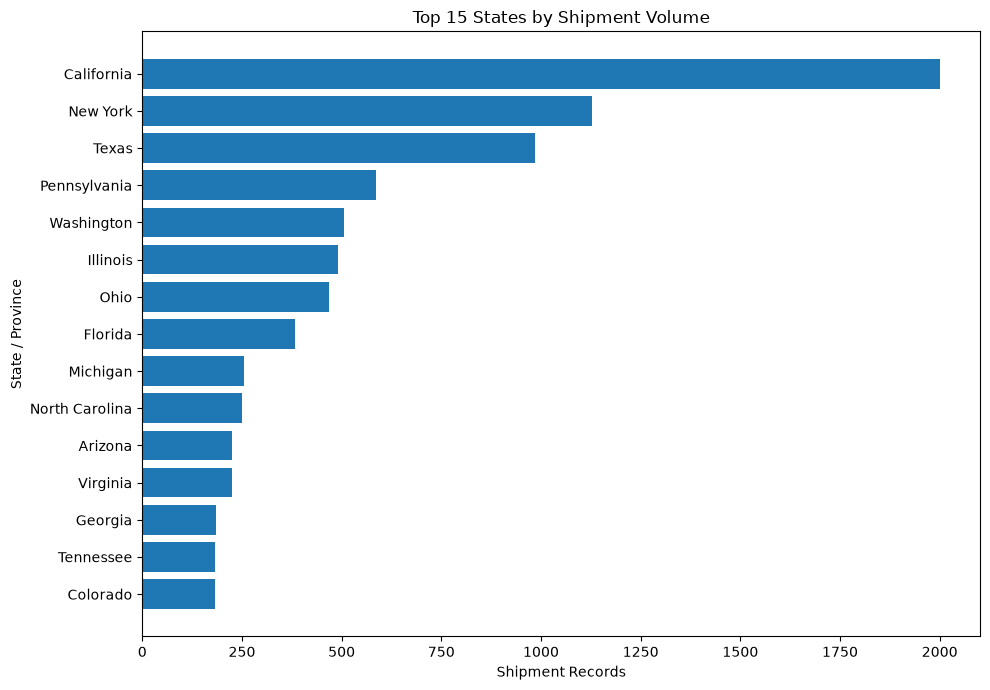

In [4]:
top_states = state_summary.head(15).sort_values(
    "Shipments", ascending=True
)

plt.figure(figsize=(10, 7))
plt.barh(top_states.index, top_states["Shipments"])
plt.title("Top 15 States by Shipment Volume")
plt.xlabel("Shipment Records")
plt.ylabel("State / Province")
plt.tight_layout()
plt.show()

In [6]:
import plotly.express as px

# Prepare US state data
us_states = state_summary.reset_index().copy()

canadian_provinces = [
    "Alberta", "British Columbia", "Manitoba",
    "New Brunswick", "Newfoundland and Labrador",
    "Nova Scotia", "Ontario", "Quebec", "Saskatchewan"
]

us_states = us_states[
    ~us_states["State/Province"].isin(canadian_provinces)
].copy()

# Convert full state names to USPS abbreviations
state_codes = {
    "Alabama": "AL", "Arizona": "AZ", "Arkansas": "AR",
    "California": "CA", "Colorado": "CO", "Connecticut": "CT",
    "Delaware": "DE", "Florida": "FL", "Georgia": "GA",
    "Idaho": "ID", "Illinois": "IL", "Indiana": "IN",
    "Iowa": "IA", "Kansas": "KS", "Kentucky": "KY",
    "Louisiana": "LA", "Maine": "ME", "Maryland": "MD",
    "Massachusetts": "MA", "Michigan": "MI", "Minnesota": "MN",
    "Mississippi": "MS", "Missouri": "MO", "Montana": "MT",
    "Nebraska": "NE", "Nevada": "NV", "New Hampshire": "NH",
    "New Jersey": "NJ", "New Mexico": "NM", "New York": "NY",
    "North Carolina": "NC", "North Dakota": "ND", "Ohio": "OH",
    "Oklahoma": "OK", "Oregon": "OR", "Pennsylvania": "PA",
    "Rhode Island": "RI", "South Carolina": "SC",
    "South Dakota": "SD", "Tennessee": "TN", "Texas": "TX",
    "Utah": "UT", "Vermont": "VT", "Virginia": "VA",
    "Washington": "WA", "West Virginia": "WV",
    "Wisconsin": "WI", "Wyoming": "WY",
    "Alaska": "AK", "Hawaii": "HI",
    "District of Columbia": "DC"
}

us_states["State_Code"] = us_states["State/Province"].map(state_codes)
us_states = us_states.dropna(subset=["State_Code"])

fig = px.choropleth(
    us_states,
    locations="State_Code",
    locationmode="USA-states",
    color="Shipments",
    scope="usa",
    color_continuous_scale="Blues",
    range_color=(0, us_states["Shipments"].max()),
    hover_name="State/Province",
    hover_data={
        "State_Code": False,
        "Shipments": True,
        "Units": True,
        "Sales": ":,.2f"
    },
    title="US Shipping Demand by State"
)

fig.update_layout(
    template="plotly_white",
    title_x=0.5,
    height=650,
    margin=dict(l=20, r=20, t=70, b=20)
)

fig.show()